Load data Set using kaggle api

In [5]:
import os
import pandas as pd
from kaggle.api.kaggle_api_extended import KaggleApi

# 1. Hardcode your Kaggle credentials directly
os.environ['KAGGLE_USERNAME'] = "vyshnav1223"
os.environ['KAGGLE_KEY'] = "KGAT_a4f3fcec3008af24795d9a147f3082aa"

# 2. Initialize and authenticate
api = KaggleApi()
api.authenticate()
print("Authenticated successfully!")

# 3. Download the dataset
dataset_slug = 'shubhamdamai/ab-testing-analysis-facebook-vs-adword'
print("Downloading dataset...")
api.dataset_download_files(dataset_slug, path='.', unzip=True)

# 4. Load the downloaded CSV into pandas
df = pd.read_csv('A_B_testing_dataset.csv')
df['date_of_campaign'] = pd.to_datetime(df['date_of_campaign'])

# 5. Verify the ingestion
print(f"Dataset successfully loaded. Dimensions: {df.shape}")
display(df.head())

Authenticated successfully!
Dataset URL: https://www.kaggle.com/datasets/shubhamdamai/ab-testing-analysis-facebook-vs-adword
Dataset successfully loaded. Dimensions: (1000, 17)


,date_of_campaign,facebook_ad_campaign,facebook_ad_views,facebook_ad_clicks,facebook_ad_conversions,facebook_cost_per_ad,facebook_ctr,facebook_conversion_rate,facebook_cost_per_click,adword_ad_campaign,adword_ad_views,adword_ad_clicks,adword_ad_conversions,adword_cost_per_ad,adword_ctr,adword_conversion_rate,adword_cost_per_click
0,2021-12-22,FACEBOOK AD,3172,62,14,141,1.95,22.58,2.27,ADWORD AD,5754,64,9,177,1.11,14.06,2.77
1,2021-12-24,FACEBOOK AD,3211,38,9,186,1.18,23.68,4.89,ADWORD AD,4954,73,6,54,1.47,8.22,0.74
2,2021-12-25,FACEBOOK AD,1936,53,15,66,2.74,28.30,1.25,ADWORD AD,4702,38,9,187,0.81,23.68,4.92
3,2021-12-25,FACEBOOK AD,1194,45,9,71,3.77,20.00,1.58,ADWORD AD,3718,58,3,161,1.56,5.17,2.78
4,2021-12-26,FACEBOOK AD,2479,44,12,174,1.77,27.27,3.95,ADWORD AD,5562,63,4,162,1.13,6.35,2.57


In [6]:
# --- Cell 2: Data Quality Assurance ---

# 1. Check for missing values and duplicates
total_nulls = df.isnull().sum().sum()
duplicate_count = df.duplicated().sum()

# 2. Print the QA Report
print("=== DATA QUALITY ASSURANCE REPORT ===")
print(f"Total Missing Values: {total_nulls}")
print(f"Duplicate Rows:       {duplicate_count}")
print(f"Date Range:           {df['date_of_campaign'].min().date()} to {df['date_of_campaign'].max().date()}")
print(f"Total Campaign Days:  {df['date_of_campaign'].nunique()} distinct days")
print("=====================================")

=== DATA QUALITY ASSURANCE REPORT ===
Total Missing Values: 0
Duplicate Rows:       0
Date Range:           2021-12-22 to 2024-12-20
Total Campaign Days:  658 distinct days


--- Campaign Summary Statistics ---


,facebook_ad_conversions,adword_ad_conversions,facebook_cost_per_click,adword_cost_per_click
count,1000.00,1000.00,1000.00,1000.00
mean,11.98,5.93,4.31,2.27
std,4.30,2.01,2.75,1.10
min,5.00,3.00,0.96,0.58
25%,8.00,4.00,2.34,1.47
50%,12.00,6.00,3.60,2.03
75%,16.00,8.00,5.61,2.80
max,19.00,9.00,16.53,6.19


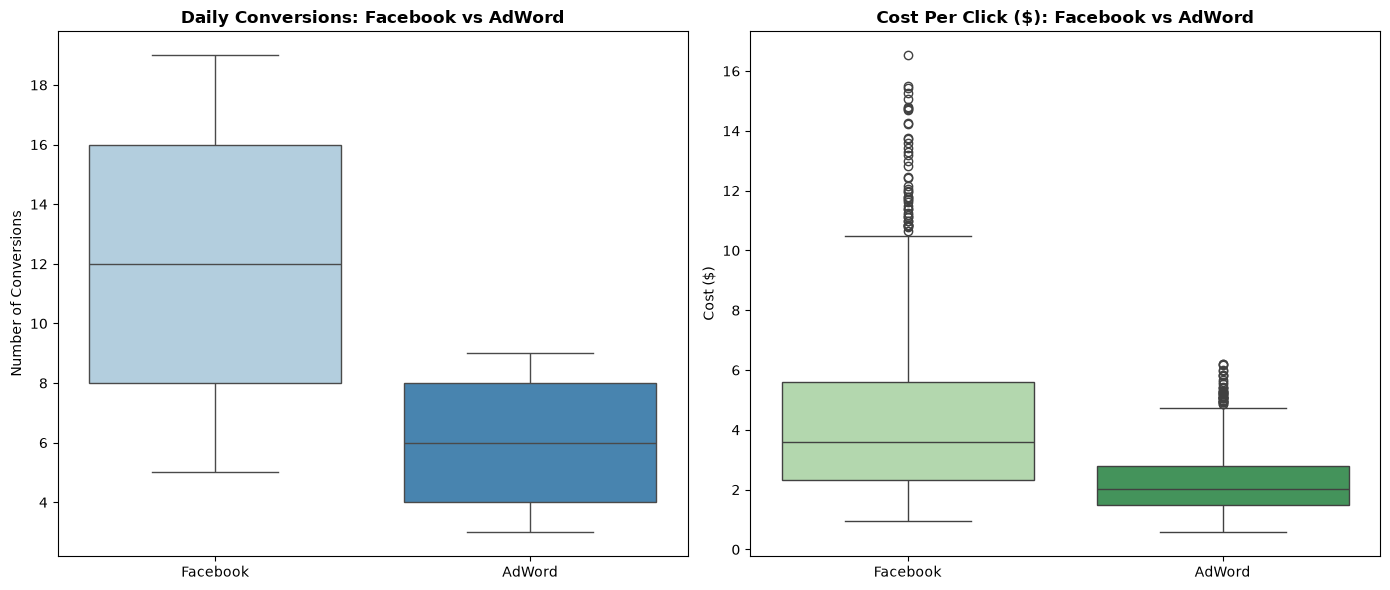

In [7]:
# --- Cell 3: Exploratory Data Analysis (EDA) ---

# Generate summary statistics
print("--- Campaign Summary Statistics ---")
display(df[['facebook_ad_conversions', 'adword_ad_conversions', 
            'facebook_cost_per_click', 'adword_cost_per_click']].describe().round(2))

# Create comparative boxplots
plt.figure(figsize=(14, 6))

# Plot 1: Conversions
plt.subplot(1, 2, 1)
sns.boxplot(data=df[['facebook_ad_conversions', 'adword_ad_conversions']], palette="Blues")
plt.title('Daily Conversions: Facebook vs AdWord', fontweight='bold')
plt.ylabel('Number of Conversions')
plt.xticks([0, 1], ['Facebook', 'AdWord'])

# Plot 2: Cost Per Click
plt.subplot(1, 2, 2)
sns.boxplot(data=df[['facebook_cost_per_click', 'adword_cost_per_click']], palette="Greens")
plt.title('Cost Per Click ($): Facebook vs AdWord', fontweight='bold')
plt.ylabel('Cost ($)')
plt.xticks([0, 1], ['Facebook', 'AdWord'])

plt.tight_layout()
plt.show()

In [8]:
# --- Cell 4: A/B Testing (Hypothesis Testing) ---
import scipy.stats as stats

# 1. Isolate the conversion columns for both platforms
fb_conversions = df['facebook_ad_conversions']
adwords_conversions = df['adword_ad_conversions']

# 2. Execute Welch's T-Test (equal_var=False handles potential variance differences)
t_stat, p_value = stats.ttest_ind(fb_conversions, adwords_conversions, equal_var=False)

# 3. Display the statistical output
print("=== A/B TESTING RESULTS: CONVERSIONS ===")
print(f"Facebook Mean Daily Conversions: {fb_conversions.mean():.2f}")
print(f"AdWords Mean Daily Conversions:  {adwords_conversions.mean():.2f}")
print("-" * 40)
print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value:     {p_value:.4e}")

# 4. Apply Business Logic to the math
alpha = 0.05
print("\n=== BUSINESS CONCLUSION ===")
if p_value < alpha:
    print("Result: STATISTICALLY SIGNIFICANT (p < 0.05)")
    print("Action: Reject the Null Hypothesis.")
    
    if fb_conversions.mean() > adwords_conversions.mean():
        print("Insight: Facebook drives significantly higher conversions than AdWords.")
        print("Recommendation: Reallocate primary marketing budget toward Facebook Ads.")
    else:
        print("Insight: AdWords drives significantly higher conversions than Facebook.")
        print("Recommendation: Reallocate primary marketing budget toward Google AdWords.")
else:
    print("Result: NOT STATISTICALLY SIGNIFICANT (p >= 0.05)")
    print("Action: Fail to reject the Null Hypothesis.")
    print("Insight: There is no mathematical difference in conversions between the platforms.")

=== A/B TESTING RESULTS: CONVERSIONS ===
Facebook Mean Daily Conversions: 11.97
AdWords Mean Daily Conversions:  5.93
----------------------------------------
T-Statistic: 40.2591
P-Value:     6.8864e-237

=== BUSINESS CONCLUSION ===
Result: STATISTICALLY SIGNIFICANT (p < 0.05)
Action: Reject the Null Hypothesis.
Insight: Facebook drives significantly higher conversions than AdWords.
Recommendation: Reallocate primary marketing budget toward Facebook Ads.


=== PREDICTIVE FORECASTING MODEL (FACEBOOK) ===
R-squared value: -0.0365 (Model explains -3.6% of the variance)
Root Mean Squared Error: +/- 4.37 conversions
Click Multiplier: 1 new click generates approx -0.0029 conversions.


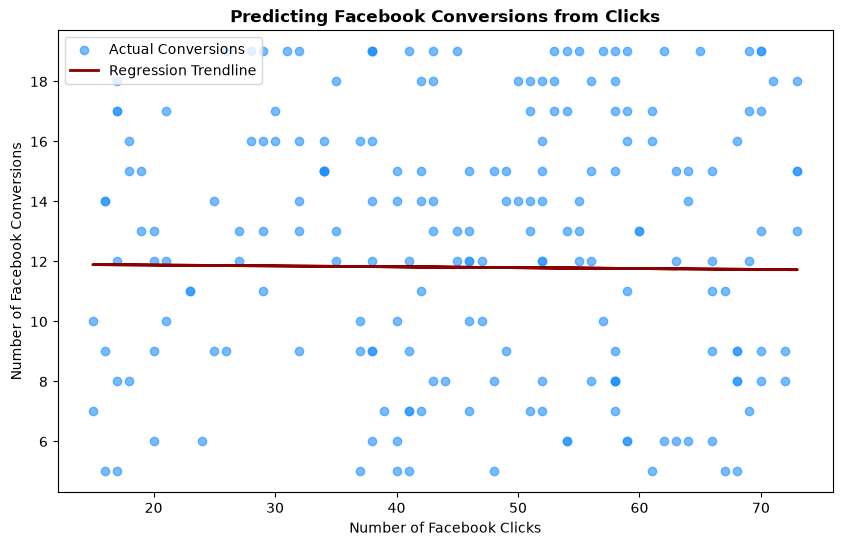

In [10]:
# --- Cell 5: Predictive Analytics (Linear Regression) ---
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 1. Isolate the variables for our winning platform (Facebook)
X = df[['facebook_ad_clicks']] 
y = df['facebook_ad_conversions'] 

# 2. Split the data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and train the regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Make predictions on the unseen test data
y_pred = model.predict(X_test)

# 5. Evaluate the model's accuracy (FIXED RMSE CALCULATION)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("=== PREDICTIVE FORECASTING MODEL (FACEBOOK) ===")
print(f"R-squared value: {r2:.4f} (Model explains {r2*100:.1f}% of the variance)")
print(f"Root Mean Squared Error: +/- {rmse:.2f} conversions")
print(f"Click Multiplier: 1 new click generates approx {model.coef_[0]:.4f} conversions.")
print("===============================================")

# 6. Visualize the prediction trendline
plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, color='dodgerblue', alpha=0.6, label='Actual Conversions')
plt.plot(X_test, y_pred, color='darkred', linewidth=2, label='Regression Trendline')
plt.title('Predicting Facebook Conversions from Clicks', fontweight='bold')
plt.xlabel('Number of Facebook Clicks')
plt.ylabel('Number of Facebook Conversions')
plt.legend()
plt.show()

=== COINTEGRATION TEST RESULTS ===
Test Statistic: -11.3581
P-Value:        0.0000
----------------------------------
Result: STATISTICALLY SIGNIFICANT (p < 0.05)
Insight: The two platforms are cointegrated.
Action: Market seasonality affects both platforms similarly. If Facebook performance dips due to market conditions, expect AdWords to dip as well.


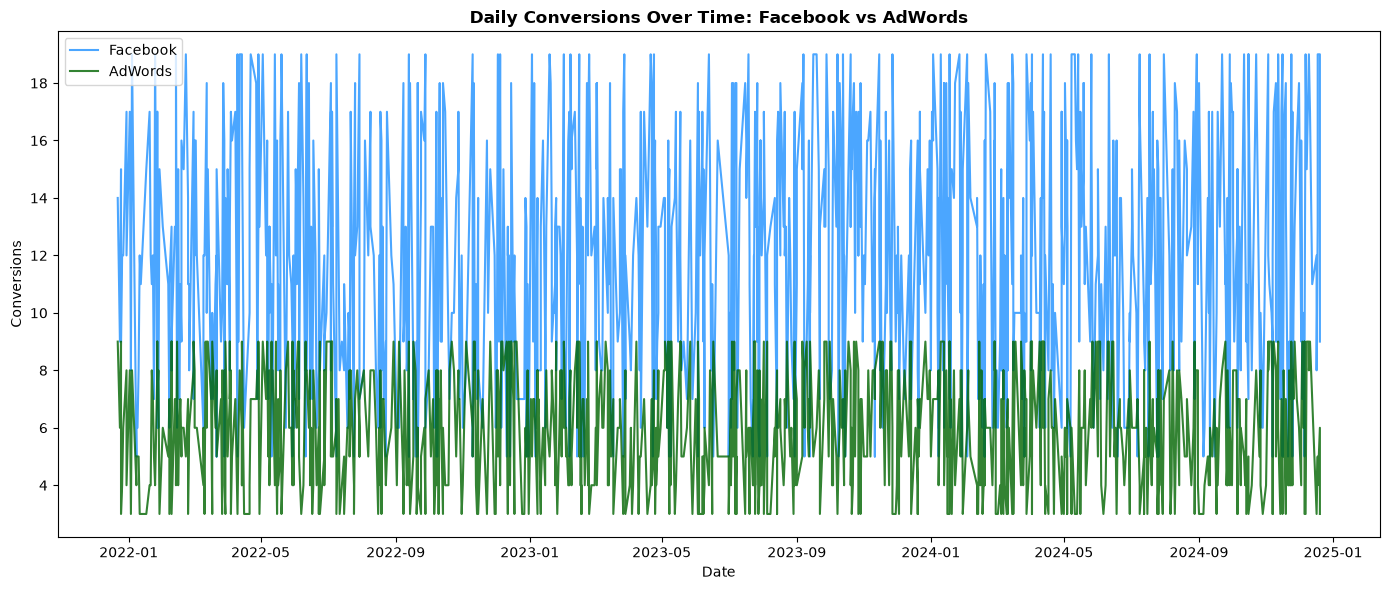

In [11]:
# --- Cell 6: Time-Series Cointegration Analysis ---
from statsmodels.tsa.stattools import coint

# 1. We test if Facebook Conversions and AdWord Conversions move together over time
score, p_value_coint, _ = coint(df['facebook_ad_conversions'], df['adword_ad_conversions'])

print("=== COINTEGRATION TEST RESULTS ===")
print(f"Test Statistic: {score:.4f}")
print(f"P-Value:        {p_value_coint:.4f}")
print("-" * 34)

# 2. Business Logic
alpha_coint = 0.05
if p_value_coint < alpha_coint:
    print("Result: STATISTICALLY SIGNIFICANT (p < 0.05)")
    print("Insight: The two platforms are cointegrated.")
    print("Action: Market seasonality affects both platforms similarly. If Facebook performance dips due to market conditions, expect AdWords to dip as well.")
else:
    print("Result: NOT STATISTICALLY SIGNIFICANT (p >= 0.05)")
    print("Insight: The two platforms are NOT cointegrated.")
    print("Action: The platforms perform independently. You can safely use AdWords to hedge against poor performance on Facebook.")

# 3. Visualize the Time Series
plt.figure(figsize=(14, 6))
plt.plot(df['date_of_campaign'], df['facebook_ad_conversions'], label='Facebook', color='dodgerblue', alpha=0.8)
plt.plot(df['date_of_campaign'], df['adword_ad_conversions'], label='AdWords', color='darkgreen', alpha=0.8)
plt.title('Daily Conversions Over Time: Facebook vs AdWords', fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Conversions')
plt.legend()
plt.tight_layout()
plt.show()